In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("./data/cs-training.csv")
df.drop(columns=["Unnamed: 0"], errors="ignore", inplace=True)
column_translation = {
    "SeriousDlqin2yrs": "2년 내 심각한 연체 여부",
    "RevolvingUtilizationOfUnsecuredLines": "무담보 신용한도 사용률",
    "age": "나이",
    "NumberOfTime30-59DaysPastDueNotWorse": "30~59일 연체 횟수",
    "DebtRatio": "부채 비율",
    "MonthlyIncome": "월 소득",
    "NumberOfOpenCreditLinesAndLoans": "개설된 신용거래 수",
    "NumberOfTimes90DaysLate": "90일 이상 연체 횟수",
    "NumberRealEstateLoansOrLines": "부동산 대출·신용한도 수",
    "NumberOfTime60-89DaysPastDueNotWorse": "60~89일 연체 횟수",
    "NumberOfDependents": "부양가족 수",
}
df.rename(columns=column_translation, inplace=True)
df.head()

,2년 내 심각한 연체 여부,무담보 신용한도 사용률,나이,30~59일 연체 횟수,부채 비율,월 소득,개설된 신용거래 수,90일 이상 연체 횟수,부동산 대출·신용한도 수,60~89일 연체 횟수,부양가족 수
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   2년 내 심각한 연체 여부  150000 non-null  int64  
 1   무담보 신용한도 사용률    150000 non-null  float64
 2   나이              150000 non-null  int64  
 3   30~59일 연체 횟수    150000 non-null  int64  
 4   부채 비율           150000 non-null  float64
 5   월 소득            120269 non-null  float64
 6   개설된 신용거래 수      150000 non-null  int64  
 7   90일 이상 연체 횟수    150000 non-null  int64  
 8   부동산 대출·신용한도 수   150000 non-null  int64  
 9   60~89일 연체 횟수    150000 non-null  int64  
 10  부양가족 수          146076 non-null  float64
dtypes: float64(4), int64(7)
memory usage: 12.6 MB


In [ ]:
# 나이 0살 삭제
df = df.drop(df[df["나이"] == 0].index).reset_index(drop=True)
df["월 소득"] = df["월 소득"].fillna(df["월 소득"].median())
df["부양가족 수"].fillna(0, inplace=True)

df["이상"] = np.select(
    [
        df["30~59일 연체 횟수"] == 96,
        df["30~59일 연체 횟수"] == 98,
    ],
    [1, 2],
    default=0,
)

df["30~59일 연체 횟수"].replace(96, 24, inplace=True)
df["30~59일 연체 횟수"].replace(98, 24, inplace=True)
df["90일 이상 연체 횟수"].replace(96, 24, inplace=True)
df["90일 이상 연체 횟수"].replace(98, 24, inplace=True)
df["60~89일 연체 횟수"].replace(96, 12, inplace=True)
df["60~89일 연체 횟수"].replace(98, 12, inplace=True)

df.describe()

,2년 내 심각한 연체 여부,무담보 신용한도 사용률,나이,30~59일 연체 횟수,부채 비율,월 소득,개설된 신용거래 수,90일 이상 연체 횟수,부동산 대출·신용한도 수,60~89일 연체 횟수,부양가족 수,이상
count,149999.000000,149999.000000,149999.000000,149999.000000,149999.000000,1.499990e+05,149999.000000,149999.000000,149999.000000,149999.000000,149999.000000,149999.000000
mean,0.066840,6.048472,52.295555,0.288389,353.007426,6.418458e+03,8.452776,0.133334,1.018233,0.086227,0.737405,0.003553
std,0.249746,249.756203,14.771298,1.223165,2037.825113,1.289044e+04,5.145964,1.121909,1.129772,0.603122,1.107020,0.084029
min,0.000000,0.000000,21.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154176,52.000000,0.000000,0.366503,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,0.000000,0.559044,63.000000,0.000000,0.868257,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000,0.000000
max,1.000000,50708.000000,109.000000,24.000000,329664.000000,3.008750e+06,58.000000,24.000000,54.000000,12.000000,20.000000,2.000000


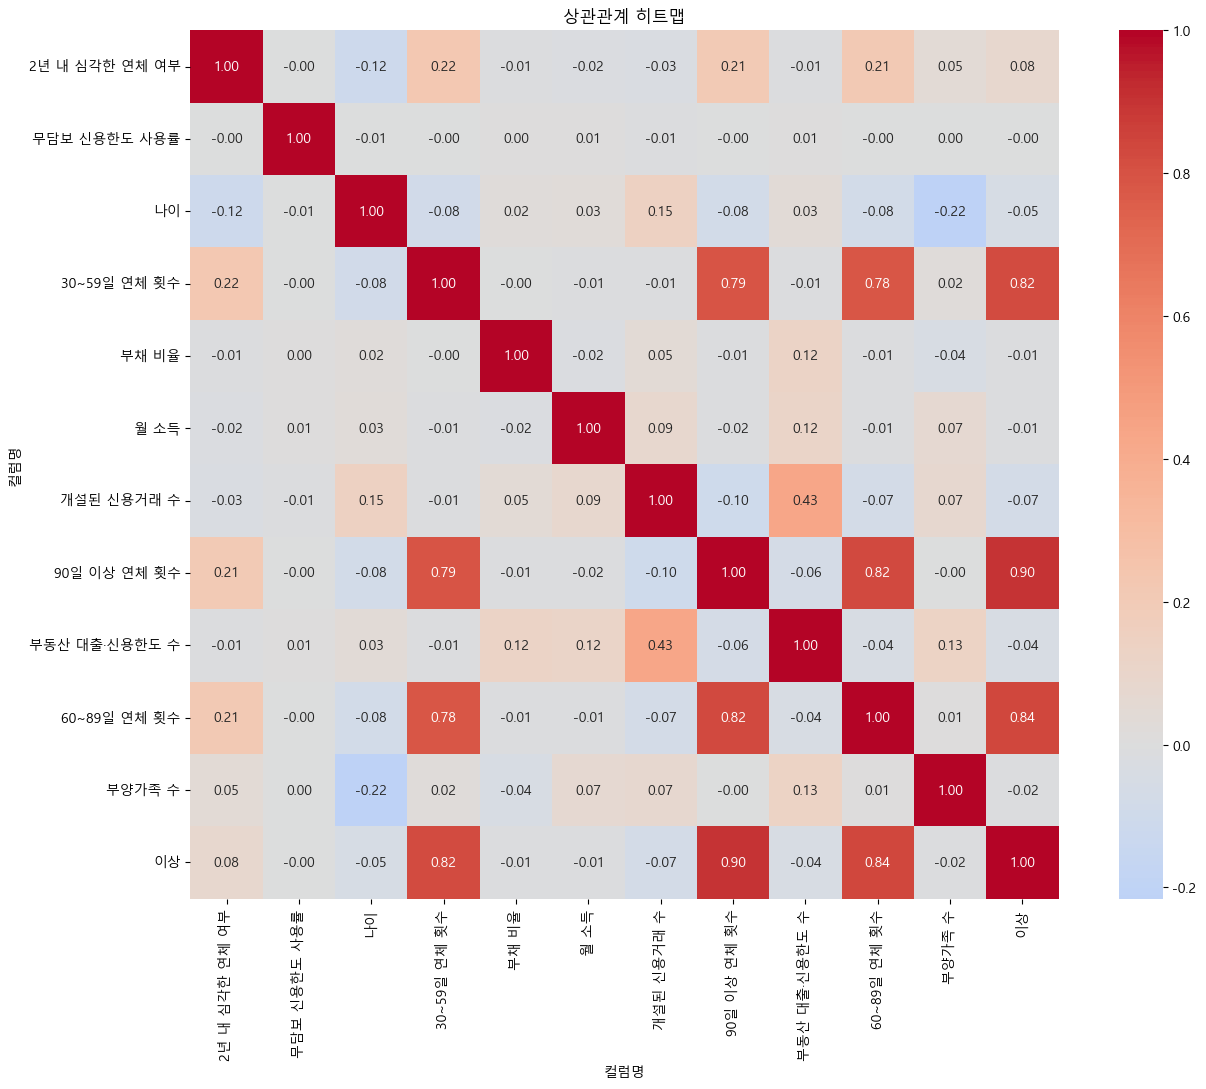

In [ ]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

numeric_columns = df.select_dtypes(include="number").columns
plot_columns = 3
plot_rows = math.ceil(len(numeric_columns) / plot_columns)

correlation = df[numeric_columns].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("상관관계 히트맵")
plt.xlabel("컬럼명")
plt.ylabel("컬럼명")
plt.tight_layout()
plt.show()

## 모델 학습과 성능 비교

이 데이터의 정답 컬럼은 0/1로 된 이진 라벨이므로, 일반 선형회귀가 아니라 분류 모델을 사용합니다. 책에 나온 LogisticRegression은 이름에 회귀가 들어가지만 이진 분류 모델입니다.

여러 모델은 학습 데이터로 학습하고 검증 데이터의 평균정밀도(AP)를 기준으로 비교합니다. 마지막 테스트 데이터는 최종 모델을 한 번 평가하는 데만 사용합니다.

In [ ]:
# 예측할 정답 컬럼의 이름을 지정합니다.
target_column = "2년 내 심각한 연체 여부"

delinquency_columns = ["30~59일 연체 횟수", "60~89일 연체 횟수", "90일 이상 연체 횟수"]

# 정답 컬럼과 CSV에 들어온 행 번호 컬럼은 입력 변수에서 제외합니다.
X = df.drop(columns=[target_column, "Unnamed: 0"], errors="ignore").copy()

# 0/1 정답값을 y로 분리합니다.
y = df[target_column].astype(int).copy()

# 각 정답값의 건수와 비율을 표로 확인합니다.
target_counts = y.value_counts().sort_index()
target_summary = pd.DataFrame({
    "건수": target_counts,
    "비율(%)": (y.value_counts(normalize=True).sort_index() * 100).round(2),
})
target_summary.index.name = "연체 라벨"
display(target_summary)

,건수,비율(%)
연체 라벨,,
0,139973,93.32
1,10026,6.68


### 학습·검증·테스트 데이터 나누기

데이터를 60% 학습, 20% 검증, 20% 테스트로 나눕니다. stratify 옵션으로 각 묶음의 연체 비율을 비슷하게 유지합니다. 검증 데이터로 모델을 고르고, 테스트 데이터는 마지막 성능 확인에만 사용합니다.

In [ ]:
from sklearn.model_selection import train_test_split

# 우선 전체 데이터의 20%를 최종 테스트용으로 따로 보관합니다.
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# 남은 80%에서 25%를 검증용으로 떼어 전체 기준 20%가 되게 합니다.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=42,
    stratify=y_development,
)

# 데이터 크기와 각 묶음의 양성 비율을 확인합니다.
print(f"학습 데이터: {X_train.shape}, 연체 비율: {y_train.mean():.3%}")
print(f"검증 데이터: {X_valid.shape}, 연체 비율: {y_valid.mean():.3%}")
print(f"테스트 데이터: {X_test.shape}, 연체 비율: {y_test.mean():.3%}")

학습 데이터: (89999, 11), 연체 비율: 6.685%
검증 데이터: (30000, 11), 연체 비율: 6.683%
테스트 데이터: (30000, 11), 연체 비율: 6.683%


### 전처리와 비교할 모델 준비

월 소득과 부양가족 수의 결측값은 학습 데이터에서 계산한 중앙값으로 채우고, 원래 결측이었는지도 표시합니다. 거리 기반 KNN과 로지스틱 회귀에는 표준화를 적용하고, 트리 계열에는 표준화를 적용하지 않습니다.

정확도만으로는 양성 비율이 낮은 데이터의 모델을 고르기 어려우므로 평균정밀도(AP)를 주 비교 기준으로 사용합니다. ROC-AUC, 정확도, 정밀도, 재현율, F1도 함께 기록합니다.

In [ ]:
import time

from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 선형·거리 기반 모델용 파이프라인: 중앙값 대체, 결측 표시, 표준화 순서로 처리합니다.
def make_scaled_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])

# 트리 계열 모델용 파이프라인: 크기 조정은 하지 않고 결측값만 처리합니다.
def make_tree_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", estimator),
    ])

# 모델별 성능과 학습된 객체를 저장할 공간을 만듭니다.
model_results = {}
fitted_models = {}

# 모델을 학습하고 검증 데이터에서 공통 지표를 계산하는 함수입니다.
def fit_and_evaluate_validation(model_name, estimator):
    # 학습 시작 시간을 기록합니다.
    start_time = time.perf_counter()

    # 학습 데이터로만 전처리 기준과 모델을 학습합니다.
    estimator.fit(X_train, y_train)

    # 검증 데이터의 연체 확률을 계산합니다.
    probabilities = estimator.predict_proba(X_valid)[:, 1]

    # 확률 0.5를 기준으로 임시 분류값을 만듭니다.
    predictions = (probabilities >= 0.5).astype(int)

    # 검증 데이터의 지표를 저장합니다.
    model_results[model_name] = {
        "모델": model_name,
        "평균정밀도(AP)": average_precision_score(y_valid, probabilities),
        "ROC-AUC": roc_auc_score(y_valid, probabilities),
        "정확도(임계값 0.5)": accuracy_score(y_valid, predictions),
        "정밀도(임계값 0.5)": precision_score(y_valid, predictions, zero_division=0),
        "재현율(임계값 0.5)": recall_score(y_valid, predictions, zero_division=0),
        "F1(임계값 0.5)": f1_score(y_valid, predictions, zero_division=0),
        "소요 시간(초)": time.perf_counter() - start_time,
    }

    # 가장 좋은 모델을 나중에 테스트할 수 있도록 학습된 객체를 저장합니다.
    fitted_models[model_name] = estimator

    # 실행 중 어느 모델이 끝났는지 간단히 표시합니다.
    print(f"{model_name} 완료 | AP={model_results[model_name]['평균정밀도(AP)']:.4f}")

In [ ]:
# 책의 LogisticRegression 예제를 사용하되 클래스 불균형 가중치를 적용합니다.
models = {
    "로지스틱 회귀": make_scaled_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    ),

    # KNN은 거리 계산을 사용하므로 표준화 파이프라인을 적용합니다.
    "K최근접 이웃": make_scaled_pipeline(
        KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1)
    ),

    # 단일 결정트리는 깊이와 최소 리프 크기를 제한해 과적합을 줄입니다.
    "결정 트리": make_tree_pipeline(
        DecisionTreeClassifier(
            max_depth=10,
            min_samples_leaf=30,
            class_weight="balanced",
            random_state=42,
        )
    ),

    # 랜덤 포레스트는 여러 결정트리의 결과를 모아 예측합니다.
    "랜덤 포레스트": make_tree_pipeline(
        RandomForestClassifier(
            n_estimators=400,
            min_samples_leaf=10,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42,
        )
    ),

    # AdaBoost는 얕은 결정트리를 순차적으로 학습해 앞선 오류에 집중합니다.
    "AdaBoost": make_tree_pipeline(
        AdaBoostClassifier(
            base_estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
            n_estimators=400,
            learning_rate=0.05,
            random_state=42,
        )
    ),
}

# 먼저 기본 분류 모델들을 검증 데이터에서 비교합니다.
for model_name, estimator in models.items():
    fit_and_evaluate_validation(model_name, estimator)

로지스틱 회귀 완료 | AP=0.3626
K최근접 이웃 완료 | AP=0.2998
결정 트리 완료 | AP=0.3578
랜덤 포레스트 완료 | AP=0.4120
AdaBoost 완료 | AP=0.3969


In [ ]:
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# 양성과 음성의 비율을 계산해 XGBoost의 클래스 가중치로 사용합니다.
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

# XGBoost는 히스토그램 방식으로 학습하고 불균형 데이터용 가중치를 적용합니다.
# Hyperopt 35회(CV AP 기준)로 찾은 설정 — 검증 AP 약 0.4147 (수동 0.4129 대비 소폭↑)
models["XGBoost"] = make_tree_pipeline(
    XGBClassifier(
        n_estimators=350,
        max_depth=4,
        min_child_weight=15,
        learning_rate=0.02,
        subsample=0.8601,
        colsample_bytree=0.67611,
        scale_pos_weight=positive_weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=4,
        random_state=42,
    )
)

# GridSearch + n_estimators 미세 조정으로 찾은 설정 (검증 AP 약 0.4156)
models["LightGBM"] = make_tree_pipeline(
    LGBMClassifier(
        n_estimators=140,
        learning_rate=0.05,
        num_leaves=31,
        class_weight="balanced",
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        n_jobs=-1,
        verbosity=-1,
        random_state=42,
    )
)

# 두 부스팅 모델도 같은 학습·검증 분할과 지표로 평가합니다.
for model_name in ["XGBoost", "LightGBM"]:
    fit_and_evaluate_validation(model_name, models[model_name])

XGBoost 완료 | AP=0.4169
LightGBM 완료 | AP=0.4131


In [ ]:
from sklearn.base import clone

# 소프트 보팅: 검증 AP 상위 트리·부스팅 조합 (XGBoost + LightGBM, 가중치 검증 AP 기준)
models["소프트 보팅"] = VotingClassifier(
    estimators=[
        ("xgb", clone(models["XGBoost"])),
        ("lgb", clone(models["LightGBM"])),
        ('랜덤 포레스트', clone(models["랜덤 포레스트"])),
    ],
    voting="soft",
    # weights=[0.8, 0.15],
    n_jobs=1,
)

# 스태킹은 학습 데이터의 교차검증 예측을 메타 모델의 입력으로 사용합니다.
# 베이스: KNN 제외, 튜닝된 XGBoost 포함 / 메타: LogisticRegression C=1.0 (검증 AP 약 0.417)
# models["스태킹"] = StackingClassifier(
#     estimators=[
#         ("tree", models["결정 트리"]),
#         ("forest", models["랜덤 포레스트"]),
#         ("adaboost", models["AdaBoost"]),
#         ("xgb", models["XGBoost"]),
#     ],
#     final_estimator=LogisticRegression(
#         C=1.0,
#         class_weight="balanced",
#         max_iter=2000,
#         random_state=42,
#     ),
#     stack_method="predict_proba",
#     cv=3,
#     passthrough=False,
#     n_jobs=1,
# )

# 두 앙상블 모델을 검증 데이터에서 평가합니다.
# for model_name in ["소프트 보팅", "스태킹"]:
for model_name in ["소프트 보팅"]:
    fit_and_evaluate_validation(model_name, models[model_name])

소프트 보팅 완료 | AP=0.4180


### Hyperopt로 XGBoost 하이퍼파라미터 탐색

4_5와 4_6의 Hyperopt 방식을 적용합니다. 학습 데이터 안에서 층화 3겹 교차검증으로 설정을 고르고, 검증 데이터와 테스트 데이터는 탐색 과정에서 사용하지 않습니다. TPE로 35개 조합을 비교하며, `n_estimators`까지 함께 탐색합니다.

In [ ]:
from hyperopt import STATUS_OK, Trials, fmin, hp, tpe
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 사전 Hyperopt 35회로 확정한 XGBoost 설정 (위 XGBoost 셀과 동일)
xgb_tuned_params = {
    "n_estimators": 300,
    "max_depth": 4,
    "min_child_weight": 10,
    "learning_rate": 0.02679,
    "subsample": 0.8601,
    "colsample_bytree": 0.67611,
}

# 탐색할 트리 깊이, 리프 조건, 학습률, 부스팅 라운드, 열·행 샘플 비율을 정의합니다.
xgb_search_space = {
    "max_depth": hp.quniform("max_depth", 2, 6, 1),
    "min_child_weight": hp.quniform("min_child_weight", 5, 12, 1),
    "learning_rate": hp.loguniform("learning_rate", np.log(0.02), np.log(0.08)),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.6, 0.9),
    "subsample": hp.uniform("subsample", 0.75, 0.95),
    "n_estimators": hp.quniform("n_estimators", 300, 800, 50),
}

# 매 조합을 학습 데이터의 동일한 층화 3겹 교차검증으로 평가합니다.
xgb_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 평균정밀도 계산에는 연체(양성) 확률 한 열만 전달합니다.
def average_precision_scorer(estimator, X_fold, y_fold):
    positive_probabilities = estimator.predict_proba(X_fold)[:, 1]
    return average_precision_score(y_fold, positive_probabilities)

# Hyperopt가 호출할 목적 함수입니다. 평균정밀도를 높이기 위해 음수 점수를 최소화합니다.
def xgb_objective(search_params):
    candidate = make_tree_pipeline(
        XGBClassifier(
            n_estimators=int(search_params["n_estimators"]),
            max_depth=int(search_params["max_depth"]),
            min_child_weight=float(search_params["min_child_weight"]),
            learning_rate=float(search_params["learning_rate"]),
            colsample_bytree=float(search_params["colsample_bytree"]),
            subsample=float(search_params["subsample"]),
            scale_pos_weight=positive_weight,
            objective="binary:logistic",
            eval_metric="aucpr",
            tree_method="hist",
            n_jobs=4,
            random_state=42,
        )
    )

    # 사용자 정의 점수 함수로 각 fold의 양성 확률만 평가합니다.
    fold_scores = cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=xgb_cv,
        scoring=average_precision_scorer,
        n_jobs=1,
    )

    # Hyperopt는 loss를 최소화하므로 AP에 음수를 붙여 반환합니다.
    return {"loss": -float(fold_scores.mean()), "status": STATUS_OK}

# 탐색 기록을 저장하고 TPE 알고리즘으로 35개 설정을 시험합니다.
hyperopt_trials = Trials()
best_xgb_params = fmin(
    fn=xgb_objective,
    space=xgb_search_space,
    algo=tpe.suggest,
    max_evals=35,
    trials=hyperopt_trials,
    rstate=np.random.default_rng(seed=42),
    show_progressbar=False,
)

# 선택된 설정을 보기 쉬운 숫자 형태로 출력합니다.
print("Hyperopt 이번 실행 최적:", {
    "n_estimators": int(best_xgb_params["n_estimators"]),
    "max_depth": int(best_xgb_params["max_depth"]),
    "min_child_weight": int(best_xgb_params["min_child_weight"]),
    "learning_rate": round(best_xgb_params["learning_rate"], 5),
    "colsample_bytree": round(best_xgb_params["colsample_bytree"], 5),
    "subsample": round(best_xgb_params["subsample"], 5),
})
print("노트북 확정 튜닝값:", xgb_tuned_params)

# 확정 튜닝값으로 XGBoost (Hyperopt) 후보를 구성합니다 (XGBoost 셀과 동일).
models["XGBoost (Hyperopt)"] = make_tree_pipeline(
    XGBClassifier(
        **xgb_tuned_params,
        scale_pos_weight=positive_weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=4,
        random_state=42,
    )
)

# 튜닝 모델도 검증 데이터에서 다른 후보들과 같은 기준으로 평가합니다.
fit_and_evaluate_validation("XGBoost (Hyperopt)", models["XGBoost (Hyperopt)"])

Hyperopt 이번 실행 최적: {'n_estimators': 400, 'max_depth': 4, 'min_child_weight': 11, 'learning_rate': 0.02022, 'colsample_bytree': 0.73629, 'subsample': 0.92076}
노트북 확정 튜닝값: {'n_estimators': 300, 'max_depth': 4, 'min_child_weight': 10, 'learning_rate': 0.02679, 'subsample': 0.8601, 'colsample_bytree': 0.67611}
XGBoost (Hyperopt) 완료 | AP=0.4161


In [ ]:
# 검증 데이터의 평균정밀도(AP)를 기준으로 모든 후보를 정렬합니다.
validation_results = (
    pd.DataFrame(model_results.values())
    .sort_values("평균정밀도(AP)", ascending=False)
    .reset_index(drop=True)
)

# 숫자 지표를 읽기 쉽게 표시합니다.
display(validation_results.style.format({
    "평균정밀도(AP)": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "정확도(임계값 0.5)": "{:.4f}",
    "정밀도(임계값 0.5)": "{:.4f}",
    "재현율(임계값 0.5)": "{:.4f}",
    "F1(임계값 0.5)": "{:.4f}",
    "소요 시간(초)": "{:.1f}",
}))

# 검증 AP가 가장 높은 모델을 선택합니다. 테스트 점수로 모델을 고르지 않습니다.
best_validation_name = validation_results.loc[0, "모델"]
print(f"검증 데이터 기준 선택 모델: {best_validation_name}")

,모델,평균정밀도(AP),ROC-AUC,정확도(임계값 0.5),정밀도(임계값 0.5),재현율(임계값 0.5),F1(임계값 0.5),소요 시간(초)
0,소프트 보팅,0.4180,0.8677,0.8416,0.2558,0.7177,0.3771,7.3
1,XGBoost,0.4169,0.8664,0.7928,0.2138,0.7845,0.3360,0.9
2,XGBoost (Hyperopt),0.4161,0.8663,0.7928,0.2139,0.7850,0.3361,0.9
3,LightGBM,0.4131,0.8671,0.8023,0.2205,0.7726,0.3431,0.6
4,랜덤 포레스트,0.4120,0.8638,0.8926,0.3322,0.6015,0.4280,5.8
5,AdaBoost,0.3969,0.8599,0.9382,0.6242,0.1905,0.2919,23.9
6,로지스틱 회귀,0.3626,0.8242,0.8594,0.2648,0.6214,0.3713,0.4
7,결정 트리,0.3578,0.8401,0.7882,0.2038,0.7466,0.3202,0.4
8,K최근접 이웃,0.2998,0.7786,0.9340,0.5190,0.1701,0.2562,9.0


검증 데이터 기준 선택 모델: 소프트 보팅


### 선택한 모델의 최종 테스트 평가

검증 AP가 가장 높은 모델을 학습+검증 데이터로 다시 학습합니다. 분류 임계값은 검증 데이터에서 F1이 가장 높은 지점으로 정하고, 테스트 데이터에서는 모델과 임계값을 더 이상 바꾸지 않고 최종 점수만 확인합니다.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# 검증 데이터에서 선택된 모델의 연체 확률을 가져옵니다.
selected_validation_model = fitted_models[best_validation_name]
validation_probabilities = selected_validation_model.predict_proba(X_valid)[:, 1]

# 검증 데이터의 정밀도-재현율 곡선에서 가능한 임계값들을 구합니다.
validation_precision, validation_recall, validation_thresholds = precision_recall_curve(
    y_valid,
    validation_probabilities,
)

# 각 임계값에서 F1 점수를 계산하고 가장 높은 임계값을 선택합니다.
validation_f1 = (
    2 * validation_precision[:-1] * validation_recall[:-1]
    / np.maximum(validation_precision[:-1] + validation_recall[:-1], 1e-12)
)
best_threshold_index = int(np.argmax(validation_f1))
best_threshold = float(validation_thresholds[best_threshold_index])
print(f"검증 데이터에서 선택한 임계값: {best_threshold:.4f}")

# 선택된 모델을 복제한 뒤 학습+검증 데이터를 합쳐 다시 학습합니다.
final_model = clone(selected_validation_model)
final_model.fit(X_development, y_development)

# 최종 테스트 데이터의 연체 확률과 임계값 기준 예측값을 구합니다.
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

# 최종 모델의 순위 성능과 분류 성능을 출력합니다.
final_test_metrics = pd.DataFrame([{
    "최종 모델": best_validation_name,
    "테스트 평균정밀도(AP)": average_precision_score(y_test, test_probabilities),
    "테스트 ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "테스트 정확도": accuracy_score(y_test, test_predictions),
    "테스트 정밀도": precision_score(y_test, test_predictions, zero_division=0),
    "테스트 재현율": recall_score(y_test, test_predictions, zero_division=0),
    "테스트 F1": f1_score(y_test, test_predictions, zero_division=0),
    "사용 임계값": best_threshold,
}])
display(final_test_metrics.style.format({
    "테스트 평균정밀도(AP)": "{:.4f}",
    "테스트 ROC-AUC": "{:.4f}",
    "테스트 정확도": "{:.4f}",
    "테스트 정밀도": "{:.4f}",
    "테스트 재현율": "{:.4f}",
    "테스트 F1": "{:.4f}",
    "사용 임계값": "{:.4f}",
}))

# 실제 연체 여부별 정밀도와 재현율을 자세히 확인합니다.
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["연체 없음", "연체"],
    zero_division=0,
))

# 혼동 행렬을 한국어 행·열 이름으로 표시합니다.
test_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["실제: 연체 없음", "실제: 연체"],
    columns=["예측: 연체 없음", "예측: 연체"],
)
display(test_confusion_matrix)

In [ ]:
from sklearn.inspection import permutation_importance

# 검증 데이터에서 각 입력 변수를 섞었을 때 AP가 얼마나 낮아지는지 계산합니다.
importance_result = permutation_importance(
    fitted_models[best_validation_name],
    X_valid,
    y_valid,
    scoring=average_precision_scorer,
    n_repeats=3,
    random_state=42,
    n_jobs=1,
)

# 변수별 평균 AP 감소량과 반복 간 변동을 표로 정리합니다.
permutation_importance_df = pd.DataFrame({
    "변수": X_valid.columns,
    "평균정밀도 감소 평균": importance_result.importances_mean,
    "평균정밀도 감소 표준편차": importance_result.importances_std,
}).sort_values("평균정밀도 감소 평균", ascending=False)

# AP를 가장 많이 낮춘 상위 10개 변수를 표시합니다.
display(permutation_importance_df.head(10).style.format({
    "평균정밀도 감소 평균": "{:.4f}",
    "평균정밀도 감소 표준편차": "{:.4f}",
}))

# 상위 변수의 중요도를 막대그래프로 그립니다.
plt.figure(figsize=(10, 6))
sns.barplot(
    data=permutation_importance_df.head(10),
    x="평균정밀도 감소 평균",
    y="변수",
)
plt.title("XGBoost 변수 중요도 (검증 AP 감소량)")
plt.xlabel("변수를 섞었을 때 감소한 평균정밀도(AP)")
plt.ylabel("변수")
plt.tight_layout()
plt.show()